# Аугментации 12-канальной ЭКГ

Команда 146 · Алексей Воронов · Чекпоинт 2

Сравниваем четыре преобразования: добавление шума, изменение амплитуды,
дрейф изолинии и временной сдвиг. У каждого метода три уровня силы.
Проверяем, как они меняют форму ЭКГ и статистические характеристики,
чтобы выбрать параметры для экспериментов с обучением.

## 1. Данные и подготовка

Используем PTB-XL 1.0.3, записи `records100`: 100 Гц, 10 секунд,
12 отведений. В выборке 175 ЭКГ от разных пациентов: по 25 записей
с единственной меткой каждого из пяти суперклассов и 50 мультиметочных.
Записи отобраны из фолдов 1–8 с seed 146. Фолды 9 и 10 оставлены
для валидации и тестирования моделей.

Подготовка из корня репозитория:

```bash
uv sync --locked
uv run python scripts/download_augmentation_subset.py
uv run jupyter lab
```

Загрузчик скачивает метаданные и выбранные сигналы в `data/`.
Ноутбук можно запускать из корня репозитория или из `notebooks/`.
Для запуска нужен `notebooks/labels.py` из ветки Ульяны `UlyShel/eda-analysis`.

Метки готовит `notebooks/labels.py` Ульяны из `ptbxl_database.csv`
и `scp_statements.csv`. Наш модуль присоединяет пути к сигналам по `ecg_id`
и отбирает выборку. Диагностические SCP-коды
сводятся к NORM, MI, STTC, CD, HYP. Учитывается наличие кода,
включая коды с likelihood 0. Записи без этих пяти меток в выборку
не входят, хотя у них могут быть другие SCP-утверждения.

In [1]:
import hashlib
import importlib.metadata
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/ecg_ptbxl/augmentation_data.py").is_file() and (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
from ecg_ptbxl.augmentation_data import CLASSES, build_manifest
from ecg_ptbxl.augmentations import (
    add_baseline_wander, add_gaussian_noise, robust_reference_scale,
    scale_amplitude, shift_signal,
)

DATA_DIR = Path(os.environ.get("PTBXL_AUG_DATA", ROOT / "data/augmentation_ptbxl_1.0.3"))
REPORT_DIR = ROOT / "reports/augmentation"
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not (DATA_DIR / "manifest.csv").is_file():
    raise FileNotFoundError("Сначала запустите: uv run python scripts/download_augmentation_subset.py")

SEED = 146
FS = 100
LEADS = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False})

manifest = pd.read_csv(DATA_DIR / "manifest.csv")
expected = build_manifest(DATA_DIR, per_class=25, multilabel_count=50, seed=SEED)
pd.testing.assert_frame_equal(manifest, expected, check_dtype=False)
assert len(manifest) == manifest.patient_id.nunique() == 175
assert manifest.ecg_id.is_unique and manifest.strat_fold.between(1, 8).all()
assert manifest.has_target_label.all()
info = json.loads((DATA_DIR / "dataset_info.json").read_text(encoding="utf-8"))
for name, expected_hash in info["metadata_sha256"].items():
    assert hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() == expected_hash
versions = {name: importlib.metadata.version(name)
            for name in ["numpy", "pandas", "scipy", "wfdb", "matplotlib", "nbformat"]}
manifest.to_csv(REPORT_DIR / "sample_manifest.csv", index=False)
(REPORT_DIR / "environment.json").write_text(
    json.dumps({"python": sys.version.split()[0], "packages": versions,
                "dataset": info}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(pd.Series({"Записей": len(manifest), "Пациентов": manifest.patient_id.nunique(),
                   "Частота, Гц": FS, "Длительность, с": 10, "Отведений": 12}))
display(manifest.groupby("sampling_group").agg(records=("ecg_id", "size"),
                                               patients=("patient_id", "nunique")))
display(manifest[CLASSES].sum().rename("Положительных меток в выборке").to_frame())

Записей            175
Пациентов          175
Частота, Гц        100
Длительность, с     10
Отведений           12
dtype: int64

,records,patients
sampling_group,,
multilabel,50,50
single_CD,25,25
single_HYP,25,25
single_MI,25,25
single_NORM,25,25
single_STTC,25,25


,Положительных меток в выборке
NORM,29
MI,54
STTC,54
CD,57
HYP,49


In [2]:
signals = {}
for row in manifest.itertuples(index=False):
    record = wfdb.rdrecord(str(DATA_DIR / row.filename_lr), physical=True)
    signal = record.p_signal
    assert signal.shape == (1000, 12) and record.fs == FS
    assert record.sig_name == LEADS and record.units == ["mV"] * 12
    assert np.isfinite(signal).all()
    assert robust_reference_scale(signal) > 0
    signals[row.ecg_id] = signal

flat_leads = sum(np.count_nonzero(np.ptp(x, axis=0) == 0) for x in signals.values())
display(Markdown(f"Прочитаны **{len(signals)}** ЭКГ; NaN/Inf нет. "
                 f"Полностью постоянных отведений в этой выборке: **{flat_leads}**. "
                 "Физические значения - **mV**, порядок отведений проверен по WFDB-заголовкам."))

Прочитаны **175** ЭКГ; NaN/Inf нет. Полностью постоянных отведений в этой выборке: **0**. Физические значения - **mV**, порядок отведений проверен по WFDB-заголовкам.

## 2. Преобразования

Каждый метод применяется отдельно. Для одной ЭКГ на всех трёх уровнях
используем тот же шум, направление изменения амплитуды и сдвига,
фазу и веса дрейфа. Так можно сравнить именно силу воздействия.

Опорный масштаб - медиана RMS по отведениям после вычитания среднего.
Постоянные каналы исключаются из расчёта. Медиана уменьшает влияние
одного отведения с большой амплитудой. На графиках сохраняются физические
единицы, без отдельной нормализации каждого сигнала.

| Метод | Три уровня силы | Как применяется |
|---|---|---|
| Шум | опорный SNR 30 / 20 / 10 dB | гауссовы возмущения |
| Изменение амплитуды | ±5 / ±15 / ±30% | общий положительный коэффициент для всех отведений |
| Дрейф изолинии | 0,1 / 0,3 / 0,6 опорного RMS | синусоида 0,3 Гц со случайной фазой и весами отведений |
| Временной сдвиг | ±0,10 / ±0,25 / ±0,50 с | перенос всех отведений; свободный край заполняется крайним значением |

Эти диапазоны выбраны для сравнения. Заданный SNR относится к опорному
масштабу; фактический SNR считаем отдельно. Для дрейфа указана медиана
абсолютных пиковых амплитуд по отведениям. В отдельном канале амплитуда
добавленной синусоиды может быть выше.

Возмущения III, aVR, aVL, aVF выводим из возмущений I и II:
`III = II-I`, `aVR = -(I+II)/2`, `aVL = I-II/2`, `aVF = II-I/2`.
Поэтому добавление шума и дрейфа не меняет исходную погрешность этих
соотношений. Это упрощённая модель помех, без моделирования электродов.

In [3]:
METHODS = ["noise", "gain", "wander", "shift"]
NAMES = {"noise": "Шум", "gain": "Амплитуда", "wander": "Дрейф", "shift": "Сдвиг"}
COLORS = {"noise": "#2676b8", "gain": "#d17b13", "wander": "#278260", "shift": "#a84d84"}
PARAMETERS = {"noise": [30., 20., 10.], "gain": [.05, .15, .30],
              "wander": [.1, .3, .6], "shift": [.1, .25, .5]}
SHORT = {"noise": ["30 dB", "20 dB", "10 dB"], "gain": ["±5%", "±15%", "±30%"],
         "wander": ["0,1 RMS", "0,3 RMS", "0,6 RMS"], "shift": ["±0,1 с", "±0,25 с", "±0,5 с"]}

def transform(signal, ecg_id, method, level):
    rng = np.random.default_rng(np.random.SeedSequence([SEED, int(ecg_id), METHODS.index(method)]))
    parameter = PARAMETERS[method][level - 1]
    extra = {"shift_samples": 0, "gain_factor": 1., "reference_snr_db": np.nan}
    if method == "noise":
        result = add_gaussian_noise(signal, parameter, rng, lead_consistent=True)
        extra["reference_snr_db"] = parameter
    elif method == "gain":
        factor = 1 + rng.choice([-1, 1]) * parameter
        result = scale_amplitude(signal, factor)
        extra["gain_factor"] = factor
    elif method == "wander":
        result = add_baseline_wander(signal, FS, parameter, .3, rng, lead_consistent=True)
    else:
        shift = int(rng.choice([-1, 1]) * round(parameter * FS))
        result = shift_signal(signal, shift)
        extra["shift_samples"] = shift
    assert result.shape == signal.shape and np.isfinite(result).all()
    return result, extra

display(pd.DataFrame([{ "Метод": NAMES[m], "Низкий": SHORT[m][0],
                       "Средний": SHORT[m][1], "Высокий": SHORT[m][2] } for m in METHODS]))

,Метод,Низкий,Средний,Высокий
0,Шум,30 dB,20 dB,10 dB
1,Амплитуда,±5%,±15%,±30%
2,Дрейф,"0,1 RMS","0,3 RMS","0,6 RMS"
3,Сдвиг,"±0,1 с","±0,25 с","±0,5 с"


## 3. Показатели

- **NRMSE** - RMS разности сигналов, делённый на опорный масштаб исходной ЭКГ.
- **Корреляция** - медиана корреляций по непостоянным отведениям.
  Она чувствительна к сдвигу по времени, но не к положительному множителю амплитуды.
- **Изменения STD, размаха и среднего |diff|.** Первые два показателя
  описывают амплитуду, последний - среднее абсолютное изменение соседних отсчётов.
- **Для сдвига** дополнительно считаем ошибку после обратного выравнивания
  на общей области и долю потерянных отсчётов.
- **Для шума и дрейфа** проверяем сохранение соотношений конечностных отведений.

Сначала считаем показатели для каждой записи, затем медиану и
межквартильный интервал (IQR) по 175 пациентам.

In [4]:
def limb_residual(signal):
    a, b = signal[:, 0], signal[:, 1]
    return np.column_stack([signal[:, 2] - (b-a), signal[:, 3] + (a+b)/2,
                            signal[:, 4] - (a-b/2), signal[:, 5] - (b-a/2)])

def relative_feature_change(before, after):
    valid = np.abs(before) > 1e-12
    return float(np.median(after[valid] / before[valid] - 1)) if valid.any() else np.nan

def measure(original, changed, shift_samples=0):
    reference = robust_reference_scale(original)
    delta_rms = float(np.sqrt(np.mean((changed-original)**2)))
    a = original - original.mean(axis=0)
    b = changed - changed.mean(axis=0)
    den = np.sqrt((a*a).sum(axis=0) * (b*b).sum(axis=0))
    valid = den > 1e-12
    correlation = np.clip((a[:, valid]*b[:, valid]).sum(axis=0)/den[valid], -1, 1)
    if shift_samples > 0:
        overlap_a, overlap_b = original[:-shift_samples], changed[shift_samples:]
    elif shift_samples < 0:
        overlap_a, overlap_b = original[-shift_samples:], changed[:shift_samples]
    else:
        overlap_a, overlap_b = original, changed
    aligned_error = float(np.sqrt(np.mean((overlap_b-overlap_a)**2))) / reference
    signal_rms = float(np.sqrt(np.mean(a*a)))
    return {
        "nrmse": delta_rms/reference,
        "median_correlation": float(np.median(correlation)),
        "std_change_pct": 100*relative_feature_change(original.std(axis=0), changed.std(axis=0)),
        "range_change_pct": 100*relative_feature_change(np.ptp(original, axis=0), np.ptp(changed, axis=0)),
        "madiff_change_pct": 100*relative_feature_change(np.abs(np.diff(original, axis=0)).mean(axis=0),
                                                       np.abs(np.diff(changed, axis=0)).mean(axis=0)),
        "realized_snr_db": 20*np.log10(signal_rms/delta_rms) if delta_rms > 0 else np.inf,
        "aligned_nrmse": aligned_error,
        "lost_fraction": abs(shift_samples)/len(original),
        "limb_residual_change_mv": float(np.max(np.abs(limb_residual(changed)-limb_residual(original)))),
    }

rows = []
for record in manifest.itertuples(index=False):
    original = signals[record.ecg_id]
    for method in METHODS:
        for level in [1, 2, 3]:
            changed, extra = transform(original, record.ecg_id, method, level)
            rows.append({"ecg_id": record.ecg_id, "patient_id": record.patient_id,
                         "sampling_group": record.sampling_group,
                         "method": method, "level": level, **extra,
                         **measure(original, changed, extra["shift_samples"])})
metrics = pd.DataFrame(rows)
metrics.loc[metrics.method != "noise", "realized_snr_db"] = np.nan
assert len(metrics) == 175 * 4 * 3
assert metrics.loc[metrics.method == "shift", "aligned_nrmse"].max() == 0
assert metrics.loc[metrics.method.isin(["noise", "wander"]), "limb_residual_change_mv"].max() < 1e-10
metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)

METRICS = ["nrmse", "median_correlation", "std_change_pct", "range_change_pct", "madiff_change_pct",
           "realized_snr_db", "aligned_nrmse", "lost_fraction", "limb_residual_change_mv"]
summary = metrics.groupby(["method", "level"])[METRICS].agg(
    ["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
summary.columns = [f"{metric}_{stat.replace('<lambda_0>', 'q25').replace('<lambda_1>', 'q75')}"
                   for metric, stat in summary.columns]
summary = summary.reindex(pd.MultiIndex.from_product([METHODS, [1, 2, 3]], names=["method", "level"]))
summary.to_csv(REPORT_DIR / "summary.csv")
metrics.groupby(["sampling_group", "method", "level"])[METRICS].median().to_csv(
    REPORT_DIR / "summary_by_group.csv")
display(summary[["nrmse_median", "nrmse_q25", "nrmse_q75", "median_correlation_median",
                 "std_change_pct_median", "madiff_change_pct_median", "lost_fraction_median"]].round(4))

nrmse_median  nrmse_q25  nrmse_q75  median_correlation_median  \
method level                                                                  
noise  1            0.0329     0.0327     0.0332                     0.9995   
       2            0.1041     0.1033     0.1049                     0.9954   
       3            0.3293     0.3267     0.3316                     0.9565   
gain   1            0.0618     0.0550     0.0696                     1.0000   
       2            0.1854     0.1651     0.2087                     1.0000   
       3            0.3707     0.3303     0.4173                     1.0000   
wander 1            0.0950     0.0812     0.1171                     0.9977   
       2            0.2850     0.2437     0.3514                     0.9798   
       3            0.5700     0.4874     0.7028                     0.9260   
shift  1            1.6664     1.4665     1.8885                     0.0280   
       2            1.6939     1.4821     1.9465                     0.0320   
       3            1.7014     1.5116     1.9713                     0.0039   

              std_change_pct_median  madiff_change_pct_median  \
method level                                                    
noise  1                     0.0558                    4.1177   
       2                     0.4673                   24.7954   
       3                     4.6235                  113.5340   
gain   1                     5.0000                    5.0000   
       2                    15.0000                   15.0000   
       3                    30.0000                   30.0000   
wander 1                     0.2154                    0.0205   
       2                     1.9804                    0.0744   
       3                     7.9490                    0.2030   
shift  1                     0.0023                   -0.4846   
       2                    -0.0769                   -1.2641   
       3                    -1.6631                   -5.7087   

              lost_fraction_median  
method level                        
noise  1                     0.000  
       2                     0.000  
       3                     0.000  
gain   1                     0.000  
       2                     0.000  
       3                     0.000  
wander 1                     0.000  
       2                     0.000  
       3                     0.000  
shift  1                     0.010  
       2                     0.025  
       3                     0.050

## 4. Примеры сигналов

Ниже одна запись с меткой STTC, отведение II. Все методы и уровни
показаны в одном масштабе. Серая линия показывает исходный сигнал, цветная показывает результат.

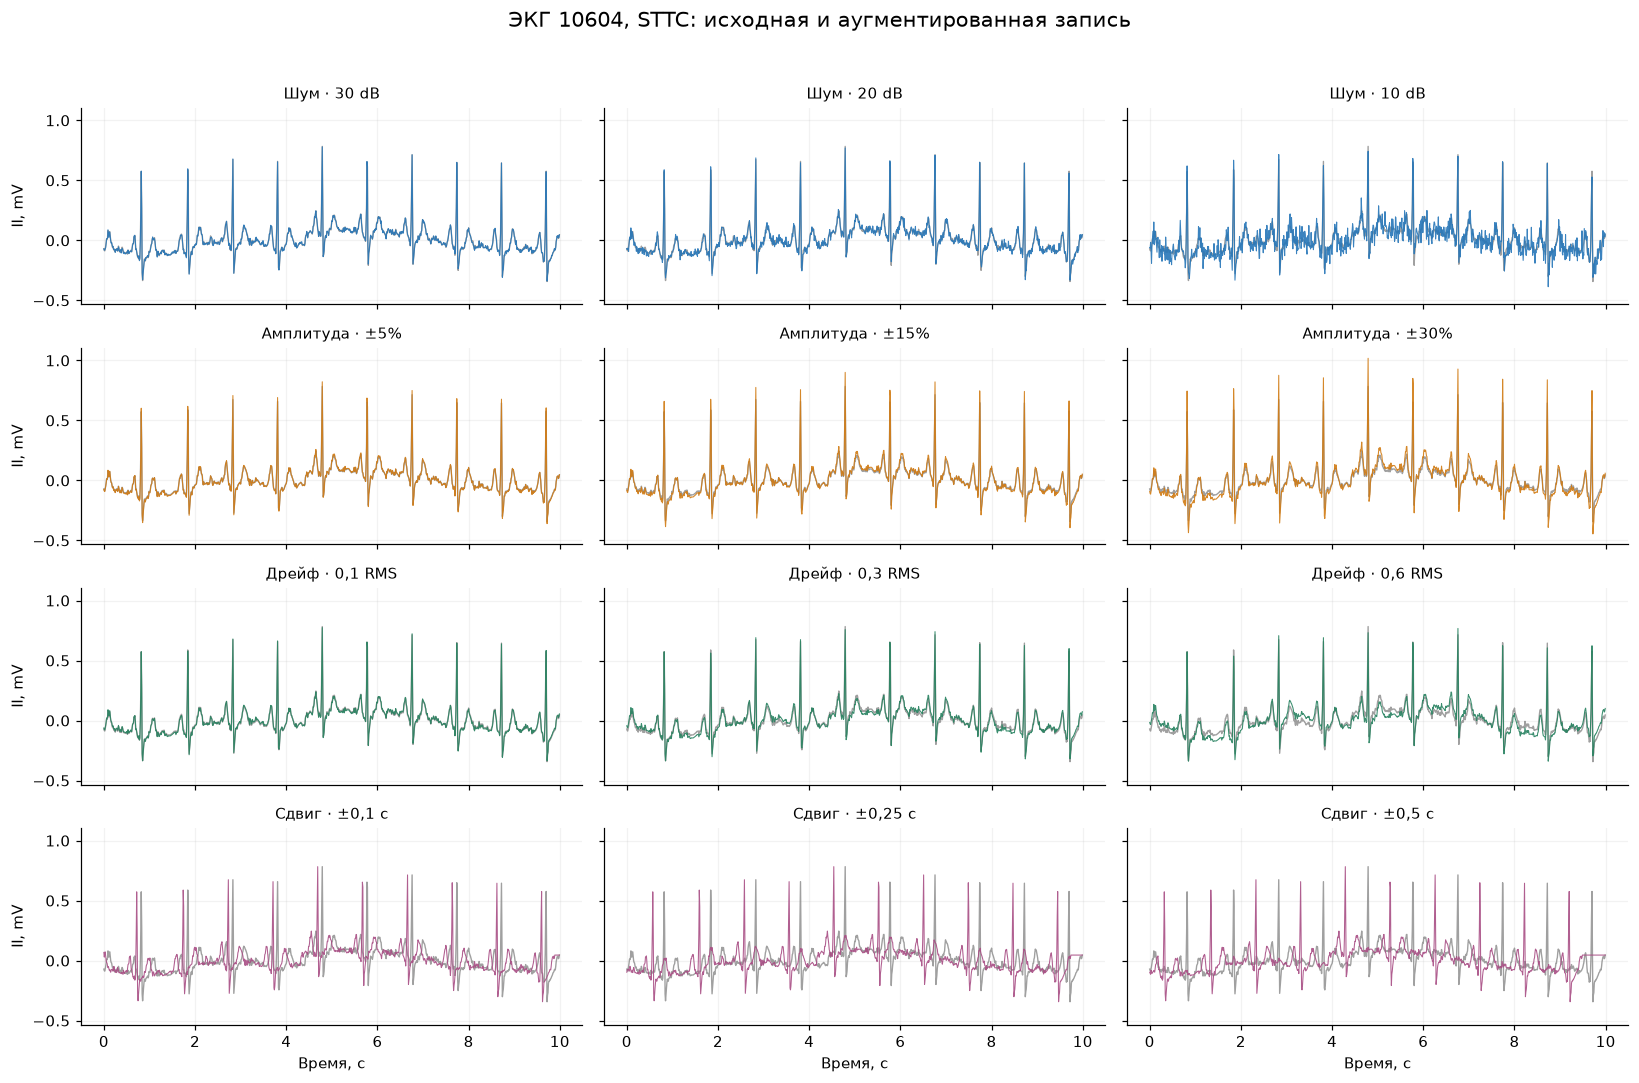

In [5]:
example_id = int(manifest.loc[manifest.sampling_group == "single_STTC", "ecg_id"].iloc[0])
original = signals[example_id]
t = np.arange(len(original))/FS
fig, axes = plt.subplots(4, 3, figsize=(15, 10), sharex=True, sharey=True)
limits = [original[:, 1]]
for i, method in enumerate(METHODS):
    for j, level in enumerate([1, 2, 3]):
        changed, _ = transform(original, example_id, method, level)
        limits.append(changed[:, 1])
        axes[i, j].plot(t, original[:, 1], color="#888888", lw=.9, alpha=.8)
        axes[i, j].plot(t, changed[:, 1], color=COLORS[method], lw=.7, alpha=.9)
        axes[i, j].set_title(f"{NAMES[method]} · {SHORT[method][j]}", fontsize=10)
        axes[i, j].grid(alpha=.16)
        if j == 0:
            axes[i, j].set_ylabel("II, mV")
        if i == 3:
            axes[i, j].set_xlabel("Время, с")
lo, hi = min(x.min() for x in limits), max(x.max() for x in limits)
axes[0, 0].set_ylim(lo-.06*(hi-lo), hi+.06*(hi-lo))
fig.suptitle(f"ЭКГ {example_id}, STTC: исходная и аугментированная запись", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .96])
fig.savefig(FIG_DIR / "01_transform_examples.png", dpi=150, bbox_inches="tight")
plt.show()

Посмотрим фрагмент 2–4 с: по одной записи каждого суперкласса
и одну мультиметочную. Для всех методов выбран средний уровень силы.
Масштаб одинаков в пределах строки.

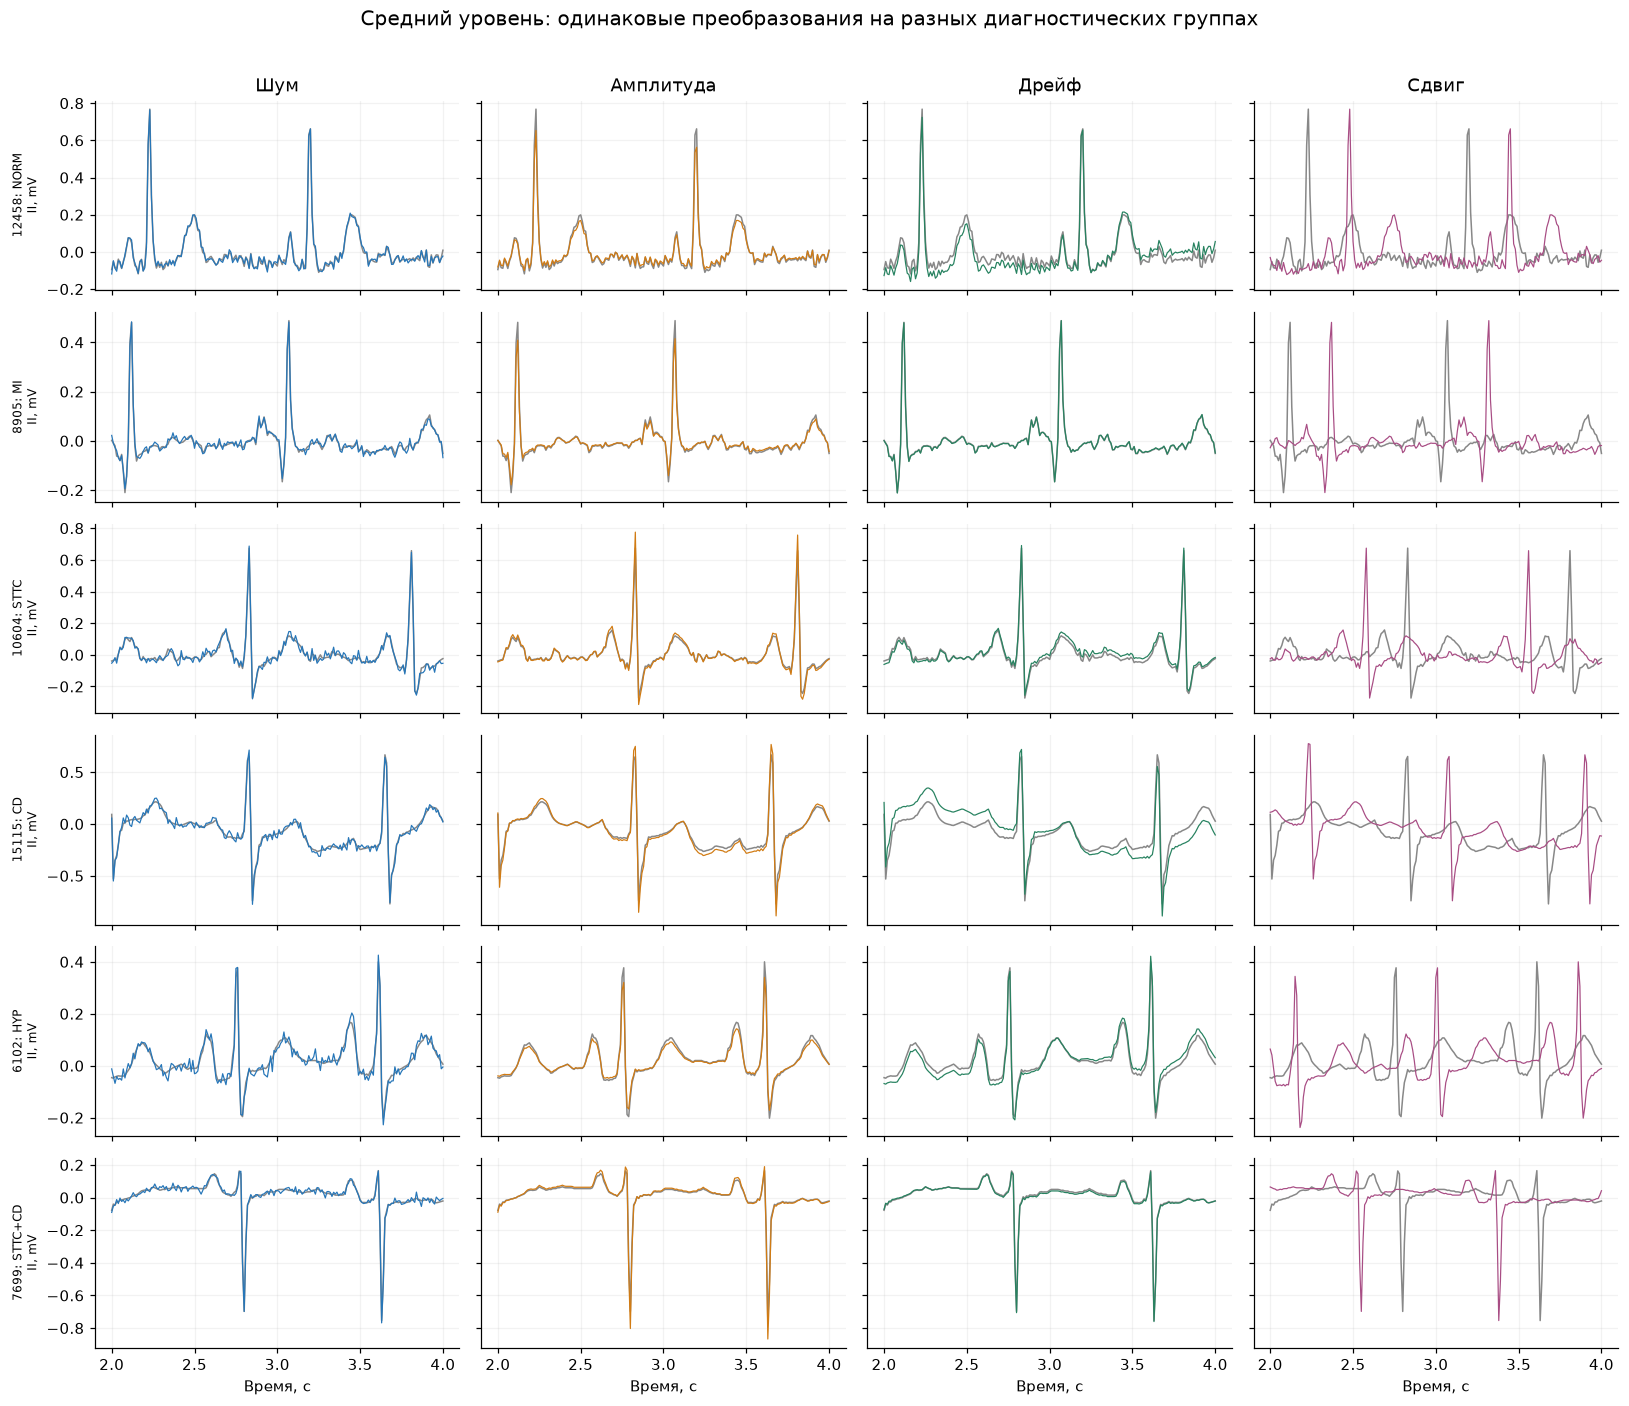

In [6]:
groups = [f"single_{name}" for name in CLASSES] + ["multilabel"]
fig, axes = plt.subplots(6, 4, figsize=(15, 13), sharex=True, sharey="row")
window = (t >= 2) & (t <= 4)
for i, group in enumerate(groups):
    record = manifest.loc[manifest.sampling_group == group].iloc[0]
    ecg_id = int(record.ecg_id)
    original = signals[ecg_id]
    label = "+".join(name for name in CLASSES if record[name] == 1)
    for j, method in enumerate(METHODS):
        changed, _ = transform(original, ecg_id, method, 2)
        axes[i, j].plot(t[window], original[window, 1], color="#888888", lw=1)
        axes[i, j].plot(t[window], changed[window, 1], color=COLORS[method], lw=.8)
        axes[i, j].grid(alpha=.16)
        if i == 0:
            axes[i, j].set_title(NAMES[method])
        if j == 0:
            axes[i, j].set_ylabel(f"{ecg_id}: {label}\nII, mV", fontsize=8)
        if i == 5:
            axes[i, j].set_xlabel("Время, с")
fig.suptitle("Средний уровень: одинаковые преобразования на разных диагностических группах", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, .97])
fig.savefig(FIG_DIR / "02_group_examples.png", dpi=150, bbox_inches="tight")
plt.show()

### Дрейф во всех 12 отведениях

Веса дрейфа различаются между отведениями. Ниже та же запись
с добавленным дрейфом 0,3 RMS. У каждой панели своя шкала,
общая для исходного и изменённого сигнала.

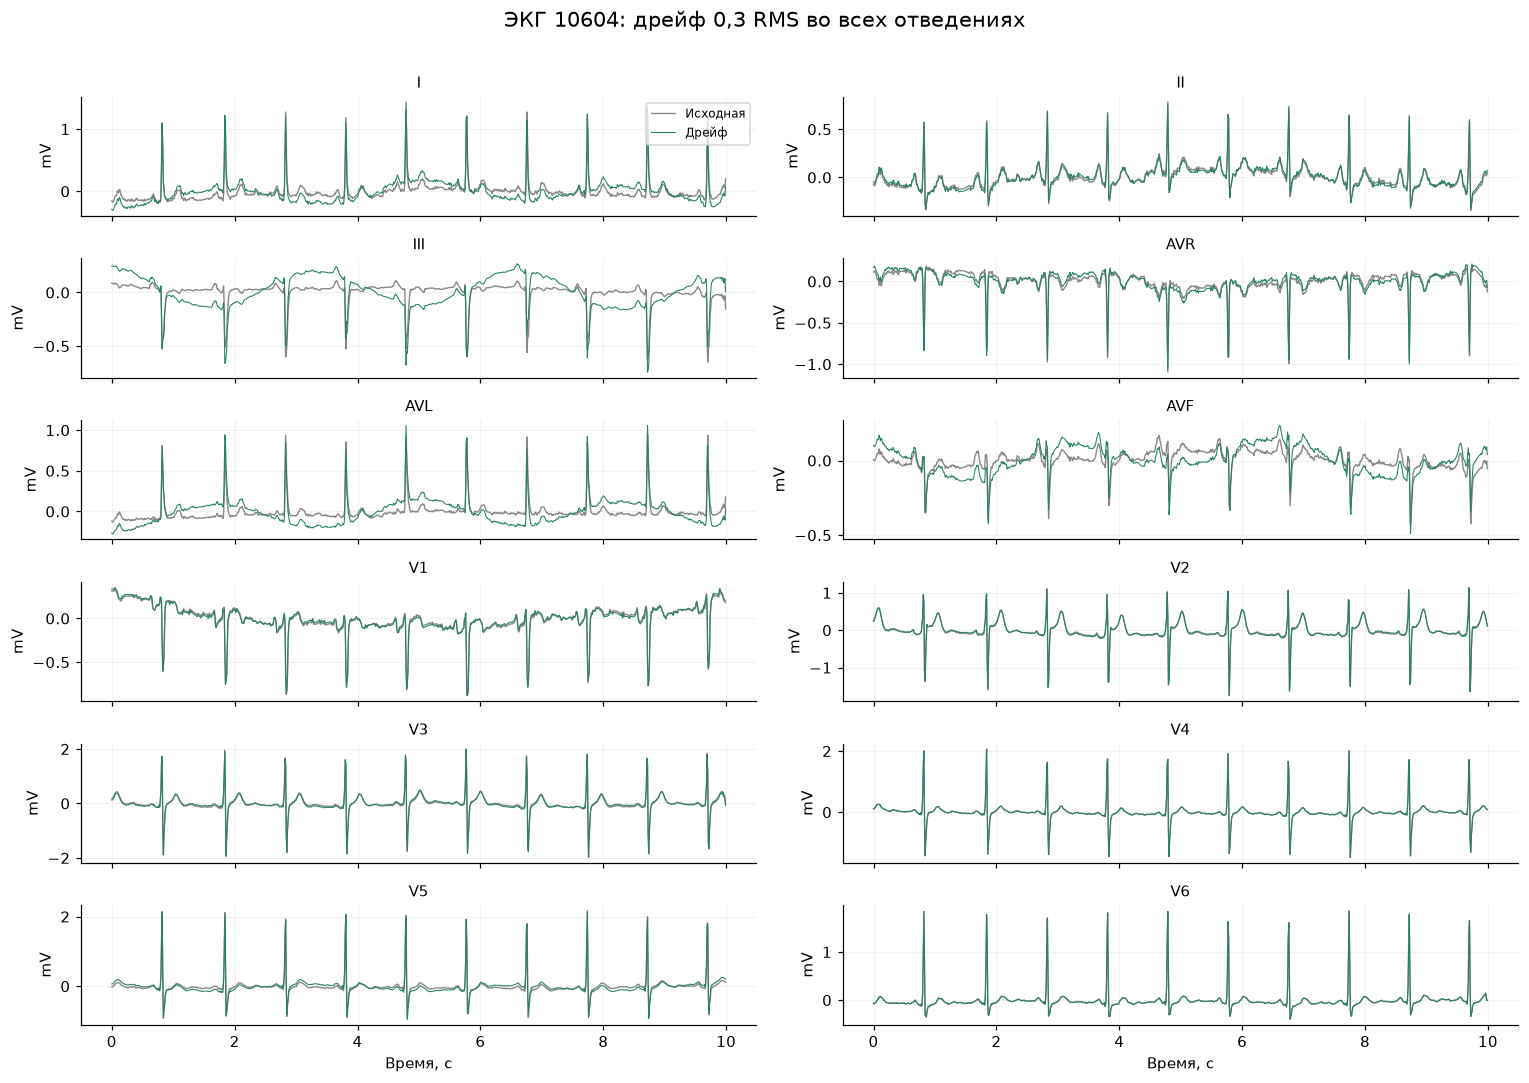

In [7]:
original = signals[example_id]
changed, _ = transform(original, example_id, "wander", 2)
fig, axes = plt.subplots(6, 2, figsize=(14, 10), sharex=True)
for lead_index, ax in enumerate(axes.flat):
    ax.plot(t, original[:, lead_index], color="#888888", lw=.9, label="Исходная")
    ax.plot(t, changed[:, lead_index], color=COLORS["wander"], lw=.7, label="Дрейф")
    ax.set_title(LEADS[lead_index], fontsize=10)
    ax.set_ylabel("mV")
    ax.grid(alpha=.16)
for ax in axes[-1]:
    ax.set_xlabel("Время, с")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle(f"ЭКГ {example_id}: дрейф 0,3 RMS во всех отведениях", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .97])
fig.savefig(FIG_DIR / "02b_all_leads.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Сравнение по всей выборке

Точки показывают медианы, отрезки - IQR. Внутри каждого цветового блока
сила преобразования растёт слева направо. Изменение амплитуды видно по STD
и размаху, даже когда корреляция равна 1.

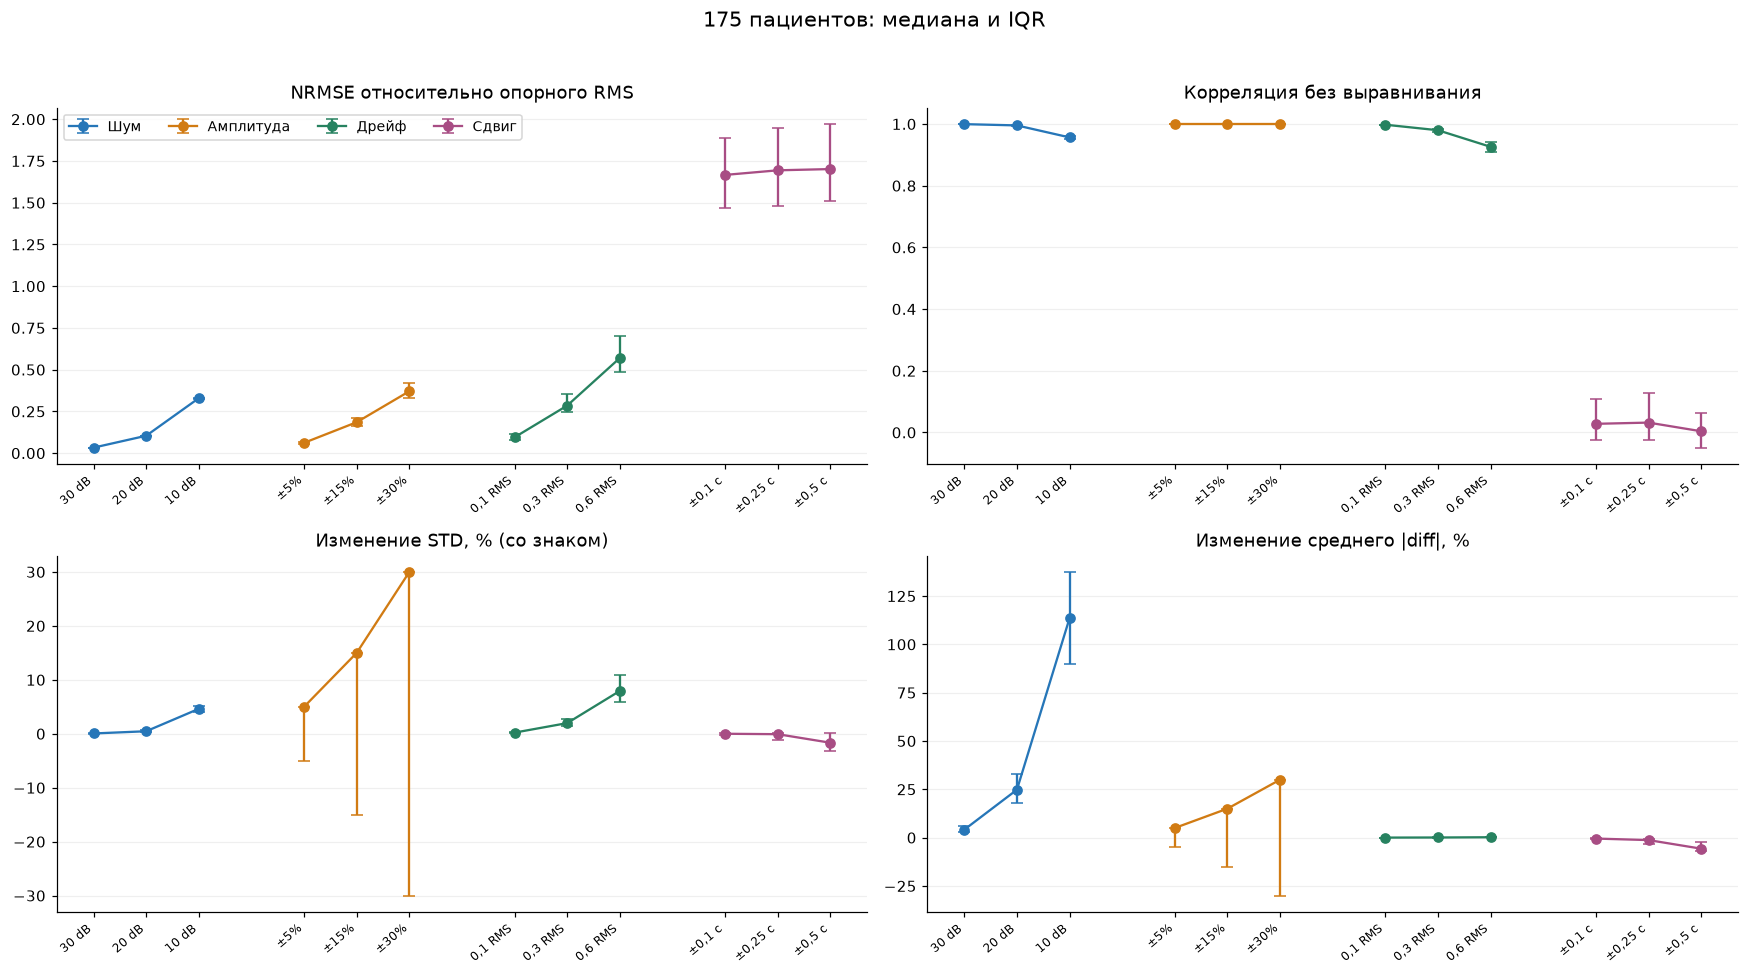

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
specs = [("nrmse", "NRMSE относительно опорного RMS"),
         ("median_correlation", "Корреляция без выравнивания"),
         ("std_change_pct", "Изменение STD, % (со знаком)"),
         ("madiff_change_pct", "Изменение среднего |diff|, %")]
for ax, (metric, title) in zip(axes.flat, specs):
    for mi, method in enumerate(METHODS):
        values = summary.loc[method]
        x = np.arange(3) + mi*4
        median = values[f"{metric}_median"].to_numpy()
        lower = median-values[f"{metric}_q25"].to_numpy()
        upper = values[f"{metric}_q75"].to_numpy()-median
        ax.errorbar(x, median, yerr=np.vstack([lower, upper]), fmt="o-", capsize=4,
                    color=COLORS[method], label=NAMES[method], lw=1.5)
    ax.set_xticks([mi*4+j for mi in range(4) for j in range(3)],
                  [SHORT[m][j] for m in METHODS for j in range(3)], rotation=40, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(axis="y", alpha=.2)
axes[0, 0].legend(ncol=4, fontsize=9)
fig.suptitle("175 пациентов: медиана и IQR", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .96])
fig.savefig(FIG_DIR / "03_distortion_summary.png", dpi=150, bbox_inches="tight")
plt.show()

Увеличение и уменьшение амплитуды разберём отдельно: общий медианный
знак зависит от того, какое направление выпало чаще. Также сравним
заданный опорный SNR шума с фактическим.

In [9]:
gain_details = metrics.loc[metrics.method == "gain"].assign(
    direction=lambda df: np.where(df.gain_factor > 1, "увеличение", "уменьшение"))
display(gain_details.groupby(["level", "direction"]).agg(
    n=("ecg_id", "size"), gain=("gain_factor", "first"),
    correlation=("median_correlation", "median"), std_change_pct=("std_change_pct", "median")))
display(metrics.loc[metrics.method == "noise"].groupby("reference_snr_db").agg(
    realized_snr_median=("realized_snr_db", "median"),
    realized_snr_q25=("realized_snr_db", lambda s: s.quantile(.25)),
    realized_snr_q75=("realized_snr_db", lambda s: s.quantile(.75))))

n  gain  correlation  std_change_pct
level direction                                        
1     увеличение  91  1.05          1.0             5.0
      уменьшение  84  0.95          1.0            -5.0
2     увеличение  91  1.15          1.0            15.0
      уменьшение  84  0.85          1.0           -15.0
3     увеличение  91  1.30          1.0            30.0
      уменьшение  84  0.70          1.0           -30.0

,realized_snr_median,realized_snr_q25,realized_snr_q75
reference_snr_db,,,
10.0,11.467237,10.459642,12.470095
20.0,21.467237,20.459642,22.470095
30.0,31.467237,30.459642,32.470095


### Сдвиг и обработка краёв

После обратного выравнивания сохранившаяся часть сигнала совпадает
с исходной. При этом один край теряется, а на другом появляется
постоянный участок. Если проявление патологии было на потерянном краю,
исходная метка может перестать соответствовать записи.

,nrmse_median,median_correlation_median,aligned_nrmse_median,lost_fraction_median
level,,,,
1,1.666424,0.028010,0.0,0.010
2,1.693940,0.031971,0.0,0.025
3,1.701412,0.003899,0.0,0.050


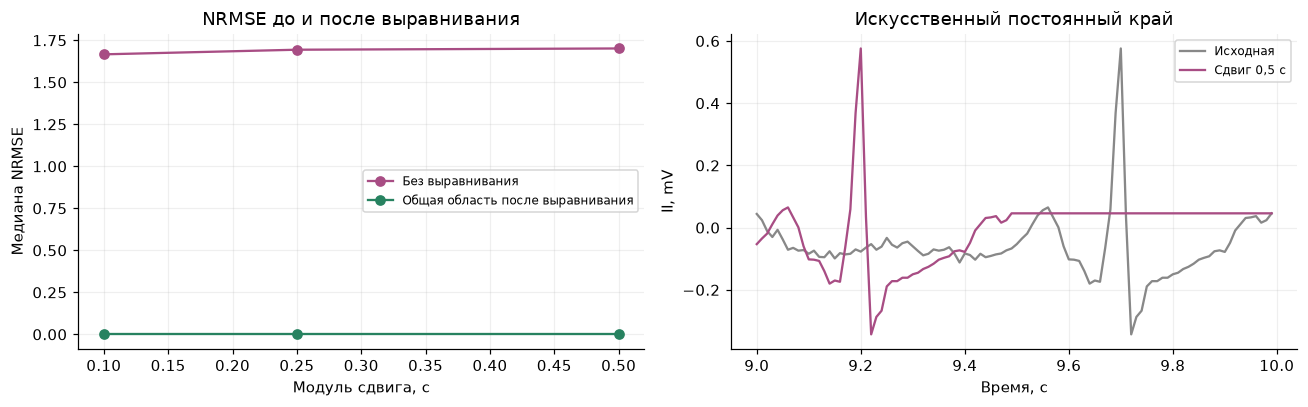

In [10]:
shift_summary = summary.loc["shift"]
display(shift_summary[["nrmse_median", "median_correlation_median", "aligned_nrmse_median",
                       "lost_fraction_median"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot([.1, .25, .5], shift_summary.nrmse_median, "o-", label="Без выравнивания", color=COLORS["shift"])
axes[0].plot([.1, .25, .5], shift_summary.aligned_nrmse_median, "o-", label="Общая область после выравнивания", color="#278260")
axes[0].set(xlabel="Модуль сдвига, с", ylabel="Медиана NRMSE", title="NRMSE до и после выравнивания")
axes[0].legend(fontsize=8)
original = signals[example_id]
changed, extra = transform(original, example_id, "shift", 3)
edge = (t <= 1) if extra["shift_samples"] > 0 else (t >= 9)
axes[1].plot(t[edge], original[edge, 1], color="#888888", label="Исходная")
axes[1].plot(t[edge], changed[edge, 1], color=COLORS["shift"], label="Сдвиг 0,5 с")
axes[1].set(xlabel="Время, с", ylabel="II, mV", title="Искусственный постоянный край")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_shift_alignment.png", dpi=150, bbox_inches="tight")
plt.show()

### Сравнение по диагностическим группам

Ниже медианный NRMSE по шести группам выборки. В каждой группе
25 или 50 записей; таблица показывает различия в силе искажения.
Статистическую значимость различий здесь не проверяем.

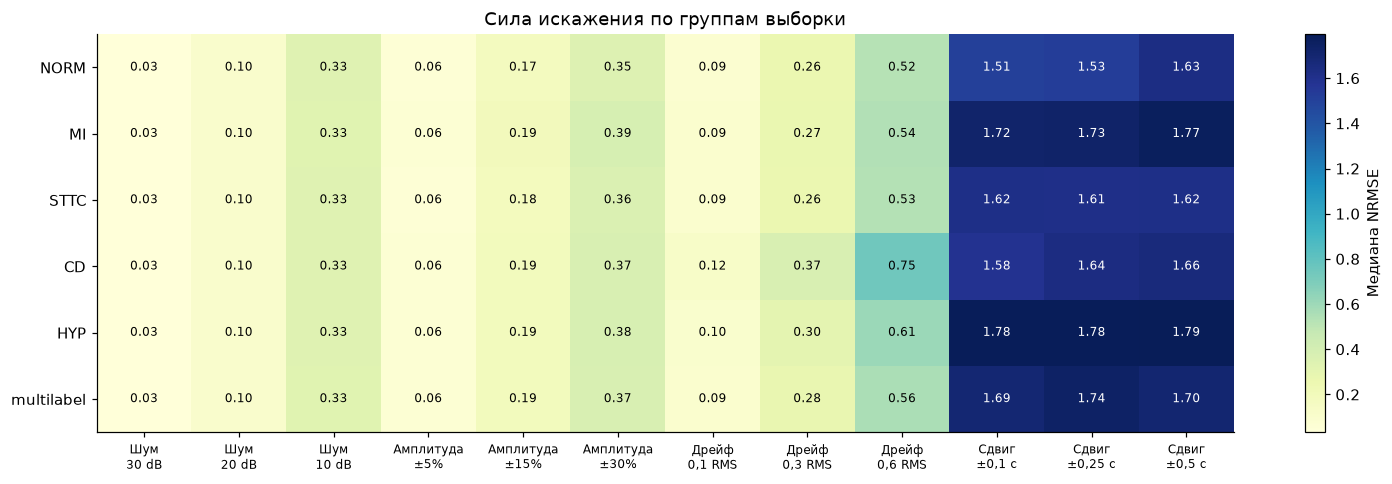

In [11]:
pivot = metrics.pivot_table(index="sampling_group", columns=["method", "level"], values="nrmse", aggfunc="median")
pivot = pivot.reindex(index=groups, columns=pd.MultiIndex.from_product([METHODS, [1, 2, 3]]))
fig, ax = plt.subplots(figsize=(14, 4.5))
image = ax.imshow(pivot, aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(6), [name.replace("single_", "") for name in groups])
ax.set_xticks(range(12), [f"{NAMES[m]}\n{SHORT[m][j]}" for m in METHODS for j in range(3)], fontsize=8)
for i in range(6):
    for j in range(12):
        value = pivot.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if value > np.nanmax(pivot.to_numpy())*.55 else "black")
fig.colorbar(image, ax=ax, label="Медиана NRMSE")
ax.set_title("Сила искажения по группам выборки")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_group_distortion.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Выводы

In [12]:
def value(method, level, metric):
    return float(summary.loc[(method, level), f"{metric}_median"])

def number(method, level, metric, digits=3):
    return f"{value(method, level, metric):.{digits}f}".replace(".", ",")

observations = f"""
### Результаты сравнения

При добавлении шума с опорным SNR от 30 до 10 dB медианный NRMSE вырос
с {number('noise', 1, 'nrmse')} до {number('noise', 3, 'nrmse')},
а корреляция снизилась с {number('noise', 1, 'median_correlation', 4)}
до {number('noise', 3, 'median_correlation', 4)}. При 10 dB среднее |diff| выросло на
{number('noise', 3, 'madiff_change_pct', 1)}% (медиана по выборке).
Сильный шум заметно меняет этот признак; при 30 dB его рост составил
{number('noise', 1, 'madiff_change_pct', 1)}%.

При изменении амплитуды корреляция осталась равной 1 даже для ±30%.
При этом STD, размах и среднее |diff| изменились на выбранные ±5/15/30%.
По одной корреляции такие преобразования оценивать нельзя.

Для дрейфа изолинии медианный NRMSE вырос с {number('wander', 1, 'nrmse')}
до {number('wander', 3, 'nrmse')}. Среднее |diff| изменилось мало:
даже на высоком уровне медианное изменение составило
{number('wander', 3, 'madiff_change_pct', 1)}%. Этот показатель слабо реагирует
на медленные колебания изолинии.

При сдвиге на 0,5 с NRMSE до выравнивания составил
{number('shift', 3, 'nrmse')}, а после выравнивания общей области - 0.
Форма сохранившегося участка не изменилась, но сдвиги на 0,1/0,25/0,5 с
удалили соответственно 1/2,5/5% исходных отсчётов. На противоположном
краю появился постоянный участок.

"""
display(Markdown(observations))
(REPORT_DIR / "conclusions.md").write_text(
    "# Аугментации ЭКГ: результаты и выводы\n\n" + observations.strip() + "\n", encoding="utf-8")
recommendations = pd.DataFrame([
    ["noise", "30 dB", "проверить первым при обучении", "20 dB отдельно; 10 dB для сильных помех"],
    ["gain", "±5%", "сравнить с исходными данными", "амплитуда важна для части диагнозов"],
    ["wander", "0.1 reference RMS", "пробовать после просмотра ST/T", "высокие уровни для сильного дрейфа"],
    ["shift", "±0.1 s", "пробовать, если потеря края допустима", "теряется 1% записи"],
], columns=["method", "candidate_setting", "recommendation", "limitation"])
recommendations.to_csv(REPORT_DIR / "recommendations.csv", index=False)


### Результаты сравнения

При добавлении шума с опорным SNR от 30 до 10 dB медианный NRMSE вырос
с 0,033 до 0,329,
а корреляция снизилась с 0,9995
до 0,9565. При 10 dB среднее |diff| выросло на
113,5% (медиана по выборке).
Сильный шум заметно меняет этот признак; при 30 dB его рост составил
4,1%.

При изменении амплитуды корреляция осталась равной 1 даже для ±30%.
При этом STD, размах и среднее |diff| изменились на выбранные ±5/15/30%.
По одной корреляции такие преобразования оценивать нельзя.

Для дрейфа изолинии медианный NRMSE вырос с 0,095
до 0,570. Среднее |diff| изменилось мало:
даже на высоком уровне медианное изменение составило
0,2%. Этот показатель слабо реагирует
на медленные колебания изолинии.

При сдвиге на 0,5 с NRMSE до выравнивания составил
1,701, а после выравнивания общей области - 0.
Форма сохранившегося участка не изменилась, но сдвиги на 0,1/0,25/0,5 с
удалили соответственно 1/2,5/5% исходных отсчётов. На противоположном
краю появился постоянный участок.
